## <font color = #0288d1>多层模型和激活函数</font>

In [1]:
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import Compose, Normalize, ToTensor
from train_cuda import train

In [2]:
mean = torch.tensor(0.1307)
std = torch.tensor(0.3081)
compose = Compose([ToTensor(), Normalize(mean, std)])
train_dataset = datasets.MNIST("./Datasets", train=True, transform=compose, download=False)
test_dataset = datasets.MNIST("./Datasets", train=False, transform=compose, download=False)
train_loader = DataLoader(train_dataset, batch_size=10000, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=2000)

## 激活函数 Activation Functions
激活函数是非线性函数。它们会压缩或弯折直线，打破深度模型与浅层模型之间的等价性。

## Sigmoid
![](../pictures/function1.png)

## Hyperbolic Tangent (TanH)

![](../pictures/function2.png)

## Rectified Linear Unit (ReLU)

![](../pictures/function3.png)

In [3]:
class ImageDeepModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 392)
        self.fc2 = nn.Linear(392, 196)
        self.fc3 = nn.Linear(196, 98)
        self.fc4 = nn.Linear(98, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        x = self.fc3(x)
        x = F.relu(x)
        return self.fc4(x)

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ImageDeepModel().to(device)
lr = 3e-3
epochs = 50
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)
train_loss, val_loss = train(
    model, train_loader, test_loader, loss_fn, optimizer, epochs, device
)

Epoch 1/50 - loss: 1.6612 - val_loss: 0.8440
Epoch 2/50 - loss: 0.6721 - val_loss: 0.4569
Epoch 3/50 - loss: 0.4245 - val_loss: 0.3439
Epoch 4/50 - loss: 0.3206 - val_loss: 0.2653
Epoch 5/50 - loss: 0.2543 - val_loss: 0.2169
Epoch 6/50 - loss: 0.2086 - val_loss: 0.1803
Epoch 7/50 - loss: 0.1727 - val_loss: 0.1560
Epoch 8/50 - loss: 0.1463 - val_loss: 0.1351
Epoch 9/50 - loss: 0.1254 - val_loss: 0.1219
Epoch 10/50 - loss: 0.1092 - val_loss: 0.1145
Epoch 11/50 - loss: 0.0964 - val_loss: 0.1023
Epoch 12/50 - loss: 0.0837 - val_loss: 0.0956
Epoch 13/50 - loss: 0.0740 - val_loss: 0.0895
Epoch 14/50 - loss: 0.0656 - val_loss: 0.0834
Epoch 15/50 - loss: 0.0576 - val_loss: 0.0815
Epoch 16/50 - loss: 0.0515 - val_loss: 0.0774
Epoch 17/50 - loss: 0.0463 - val_loss: 0.0776
Epoch 18/50 - loss: 0.0421 - val_loss: 0.0739
Epoch 19/50 - loss: 0.0373 - val_loss: 0.0722
Epoch 20/50 - loss: 0.0329 - val_loss: 0.0722
Epoch 21/50 - loss: 0.0296 - val_loss: 0.0697
Epoch 22/50 - loss: 0.0264 - val_loss: 0.07

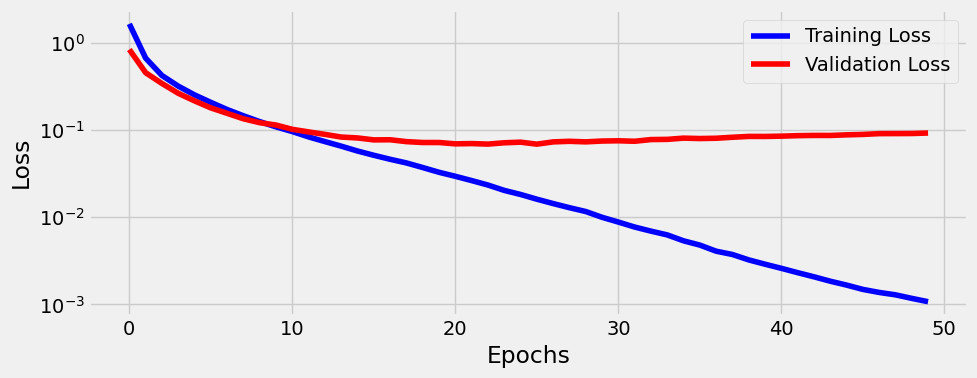

In [5]:
import matplotlib.pyplot as plt

plt.style.use("fivethirtyeight")


def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_loss, label="Training Loss", c="b")
    plt.plot(val_loss, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()

In [6]:
import torchmetrics

accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
for _, (x, y) in enumerate(test_loader):
    x, y = x.to(device), y.to(device)
    yhat = model(x)
    accuracy(yhat, y)
accuracy.compute()
print(f"Test Accuracy: {accuracy.compute().item() * 100:.2f}%")

Test Accuracy: 98.07%


/tmp/ipykernel_837805/4100894574.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  img = wrong_imgs[i][0] * std.numpy() + mean.numpy()


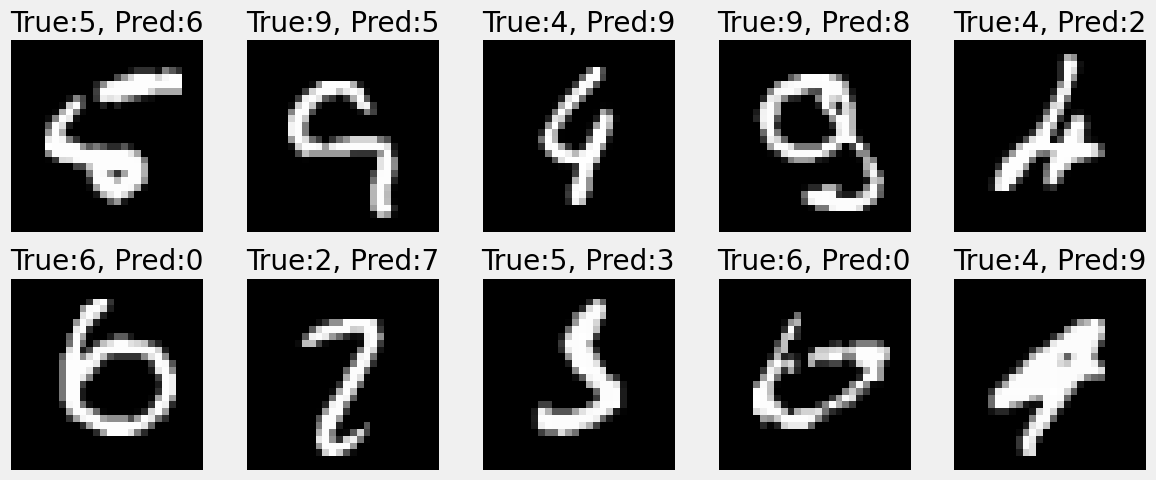

In [7]:
# ========== 追加：找出测试集前10个识别错误的样本并绘图 ==========
model.eval()
wrong_imgs = []
wrong_labels_true = []
wrong_labels_pred = []

with torch.inference_mode():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        pred = torch.argmax(logits, dim=1)

        # 找出本batch里预测不等于真值的索引
        mask = pred != y
        wrong_x_batch = x[mask]
        wrong_y_true_batch = y[mask]
        wrong_y_pred_batch = pred[mask]

        # 逐个加入，凑够10张就停
        for img, yt, yp in zip(wrong_x_batch, wrong_y_true_batch, wrong_y_pred_batch):
            wrong_imgs.append(img.cpu())
            wrong_labels_true.append(yt.item())
            wrong_labels_pred.append(yp.item())
            if len(wrong_imgs) >= 10:
                break
        if len(wrong_imgs) >= 10:
            break

# 绘图
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i+1)
    # 反归一化：img = img * std + mean
    img = wrong_imgs[i][0] * std.numpy() + mean.numpy()
    plt.imshow(img, cmap="gray")
    plt.title(f"True:{wrong_labels_true[i]}, Pred:{wrong_labels_pred[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()
